#  Финтех-приложение для онлайн-торговли финансовыми активами

SollmaFin — финтех‑приложение для онлайн‑торговли финансовыми активами (акции, валюта, криптовалюта, ETF и др.) на рынке Латинской Америки (Мексика, Бразилия, Колумбия, Аргентина). Целевая аудитория — начинающие инвесторы. Доступ — через мобильное приложение или веб‑версию.

Из‑за низкой финансовой грамотности пользователи нередко выбирают высокорисковые активы и теряют деньги — это снижает вовлечённость. Чтобы решить проблему, команда обновила онбординг: добавила подробную информацию об активах и рисках. При этом есть риск, что детальное обучение отпугнёт новичков от первых вложений.

Для проверки влияния обновлённого онбординга провели A/B‑эксперимент (2–15 июня 2025 года) с новыми пользователями:

- контрольная группа — стандартный онбординг;
- тестовая группа — онбординг с обучением по рискам и активам.
Активность анализировали в течение недели.

Гипотезы:

обучающий онбординг повысит понимание принципов инвестирования и частоту открытия второго депозита;
информация о рисках может снизить конверсию в первый депозит;
после нового онбординга пользователи, выбирающие высокорисковые активы, будут чаще возвращаться и открывать второй депозит.
Метрики эксперимента:

- ключевая — средняя сумма всех депозитов на пользователя;
- барьерная — конверсия из регистрации в первый депозит;
- вспомогательные — конверсия из первого депозита во второй и средняя сумма депозитов на платящего пользователя.

Задачи анализа:

1. Изучить исторические данные (поведение новых пользователей, сегментацию, этапы воронки, метрики депозитов).
2. Проанализировать результаты A/B‑теста: сравнить группы, оценить статистическую значимость, исследовать влияние онбординга на платящих пользователей (в том числе через бутстрап‑анализ перцентилей депозитов). Цель — оценить эффект на бизнес‑метрики, выявить точки роста и подготовить рекомендации по UX и монетизации.


### Данные

1. Датасет `/datasets/pa_sollmafin_hist.csv` содержит исторические данные о ключевых действиях новых пользователей, привлечённых в период с 1 апреля по 1 июня 2025 года включительно. В датасете собраны действия пользователей до оформления второго депозита.
2. Датасет `/datasets/pa_sollmafin_abt.csv` содержит данные А/В-эксперимента — все действия новых пользователей, которые зарегистрировались со 2 по 15 июня 2025 года включительно. Данные собраны в рамках проверки гипотезы о влиянии нового онбординга на поведение и активность пользователей. Пользователи уже распределены по группам А/В-эксперимента.

Общие поля датасетов:
- `user_id` — уникальный идентификатор пользователя;
- `country_code` — код страны пользователя в формате ISO (например, `BR` — Бразилия, `MX` — Мексика, `AR` — Аргентина, `CO` — Колумбия);
- `platform` — устройство, с которого пользователь взаимодействует с продуктом: mobile или web;
- `first_ts` — время первого появления пользователя в системе;
- `first_dt` — дата первого появления пользователя (без времени);
- `event_ts` — время события;
- `event_name` — название события;
- `amount` — сумма пополнения депозита;
- `asset` — тип приобретённого актива;
- `risk_level` — уровень риска актива: low — низкий риск, medium — средний риск, high — высокий риск.

В датасете `/datasets/pa_sollmafin_abt.csv` содержатся два дополнительных поля:
- `ab_test` — название А/В-эксперимента;
- `group` — пользовательская группа А/В-эксперимента.


### План проекта
1. Загрузка исторические данные и их предобработка
2. Исследовательский анализ исторических данных
3. Исследование результатов А/В эксперимента
4. Анализ изменений суммы депозитов на платящего пользователя
5. Выводы

---

## Часть 1

### 1. Загрузка исторических данных и их предобработка

Загружаем данные из датасета `/datasets/pa_sollmafin_hist.csv` и получаем основную информацию о них.
Проведим предобработку. Зафиксируем основную информацию о данных и предобработке в кратком промежуточном выводе.

Для начала загрузим данные и получим информацию о них.<br>
В том числе посмотрим на:
- количество уникальных значений в некоторых столбцах;
- уникальные значения категориальных переменных;
- наличие явных и неявных дубликатов;
- количество и долю пропусков;
- временные диапазоны столбцов с датой.

In [ ]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

# Загружаем библиотеки для работы с массивами и математическими операциями
import numpy as np

# Импортируем Z-тест для проверки равенства долей (конверсий) в группах
from statsmodels.stats.proportion import proportions_ztest

# Импортируем T-тест Стьюдента
from scipy.stats import ttest_ind

# Отключаем предупреждения
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Выгружаем данные в датафрейм и приведем к типу datetime64 столцы с датой и временем
sollmafin_hist_df = pd.read_csv('https://code.s3.yandex.net/datasets/pa_sollmafin_hist.csv', parse_dates=['first_ts', 'first_dt', 'event_ts'])

In [ ]:
# Выведем первые 5 строк и информации о датасете
display(sollmafin_hist_df.head(5))
display(sollmafin_hist_df.info())

,user_id,country_code,platform,first_ts,first_dt,event_ts,event_name,amount,asset,risk_level
0,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 19:55:51,install / open_web,NaN,NaN,NaN
1,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 19:55:59,introduction,NaN,NaN,NaN
2,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 23:46:06,registration,NaN,NaN,NaN
3,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 23:46:15,main_page,NaN,NaN,NaN
4,548ac59f-656d-4110-80d2-49f0a217f08a,BR,mobile,2025-04-02 19:55:51,2025-04-02,2025-04-02 23:47:59,onboarding_complete,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238059 entries, 0 to 238058
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   user_id       238059 non-null  object        
 1   country_code  238059 non-null  object        
 2   platform      238059 non-null  object        
 3   first_ts      238059 non-null  datetime64[ns]
 4   first_dt      238059 non-null  datetime64[ns]
 5   event_ts      238059 non-null  datetime64[ns]
 6   event_name    238059 non-null  object        
 7   amount        33093 non-null   float64       
 8   asset         15392 non-null   object        
 9   risk_level    15392 non-null   object        
dtypes: datetime64[ns](3), float64(1), object(6)
memory usage: 18.2+ MB


None

In [ ]:
# Отобразим количество уникальных значений в столбцах датафрейма
print('Количество уникальных значений в столбцах датафрейма\n'
      f'Размер датафрейма: {sollmafin_hist_df.shape[0]}\n')

for column in ['user_id', 'first_ts', 'first_dt', 'event_ts', 'amount']:
    count = sollmafin_hist_df[column].nunique()
    print(f'Количество уникальных значений в {column}: {count}\n')

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 238059

Количество уникальных значений в user_id: 41032

Количество уникальных значений в first_ts: 40830

Количество уникальных значений в first_dt: 62

Количество уникальных значений в event_ts: 232515

Количество уникальных значений в amount: 291



In [ ]:
# Познакомимся с уникальными значениями в столбцах (ограничим число отображения до 15)
for column in ['country_code', 'platform', 'event_name', 'asset', 'risk_level']:
    unique_vals = sollmafin_hist_df[column].unique()
    total_count = len(unique_vals)
        # Если уникальных значений больше 15, показываем сокращенный вывод
    if total_count > 20:
        print(f'{column}: {unique_vals[:15]}\n')
    else:
        print(f'{column}: {unique_vals}\n')

country_code: ['BR' 'AR' 'CO' 'MX']

platform: ['mobile' 'web']

event_name: ['install / open_web' 'introduction' 'registration' 'main_page'
 'onboarding_complete' 'first_deposit' 'asset_purchase' 'second_deposit']

asset: [nan 'stock' 'option' 'crypto']

risk_level: [nan 'medium' 'high' 'low']



In [ ]:
# Проверим датасет на наличие полных (явных) дубликатов
duplicates = sollmafin_hist_df[sollmafin_hist_df.duplicated(keep=False)]
if duplicates.empty:
    print('Дубликатов нет\n')
else:
    print(f'Найдено дубликатов: {len(duplicates)} строк\n')

Дубликатов нет



In [ ]:
# Проверяем на неявные дубликаты поля - id пользователя и временя события
duplicates = sollmafin_hist_df.duplicated(subset=['user_id', 'event_ts']).sum()
print(f'Количество неявных дубликатов по user_id и event_ts: {duplicates}')

Количество неявных дубликатов по user_id и event_ts: 0


In [ ]:
# Отобразим абсолютное и относительное количество пропусков в датасете
missing_stats = pd.DataFrame({
        'Кол-во пропусков': sollmafin_hist_df.isnull().sum(),
        'Доля пропусков': sollmafin_hist_df.isnull().mean().round(3)
})
missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]
display(missing_stats)

,Кол-во пропусков,Доля пропусков
amount,204966,0.861
asset,222667,0.935
risk_level,222667,0.935


In [ ]:
# Опеределим временные диапазоны столбцов с датой
columns = ['first_ts', 'first_dt', 'event_ts']

for column in columns:
    time_min, time_man = sollmafin_hist_df[column].min(), sollmafin_hist_df[column].max()
    print(f'{column}: {time_min} - {time_man}\n')


first_ts: 2025-04-01 00:06:34 - 2025-06-01 23:59:52

first_dt: 2025-04-01 00:00:00 - 2025-06-01 00:00:00

event_ts: 2025-04-01 00:06:34 - 2025-06-09 20:24:42



**Описание данных после предварительного знакомства с датасетом**<br>
Датасет `pa_sollmafin_hist.csv` состоит из 10 полей и 238058 записей о действиях новых пользователей приложения SollmaFin, привлечённых в период с 1 апреля по 1 июня 2025 года включительно.

*Пользовательская база*
- 41032 уникальных пользователя

*География и устройства*
- Пользователи распределены по 4 странам: `BR` — Бразилия, `MX` — Мексика, `AR` — Аргентина, `CO` — Колумбия
- Используются 2 типа устройств:`mobile` и `web`.

*Событийная часть*
- 238058 пользовательских событий
- 33093 пополнений актива
- данные охватывают события от установки/открытия сайта до второго депозита (`event_name`): `install / open_web`, `introduction`, `registration`, `main_page`, `onboarding_complete`, `first_deposit`, `asset_purchase`, `second_deposit`.

*Временной диапозон*
- датасет содержит сведения о действиях пользователей, привлеченных с 1 апреля по 1 июня 2025
- временной диапозон пользовательских событий захватывает начало июня 2025 года: с 1 апреля по 9 июня

*Качество данных*
- явные и неявные дубликаты отсутствуют
- пропуски в полях с суммой пополнения депозита (`amount`), типе приобретённого актива и уровне риска актива носят закономерный характер: для первого поля пропущены 86% записей, для второго и третьего 93% записей

*Тип данных*
- типы данных соответствуют значениям столбцов
- для поля `amount` можно понизить разрядность


**Предобработка данных** <br>
Понизим разрядность `amount`.

In [ ]:
# Понизим разрядность amount с типом данных float64
sollmafin_hist_df['amount'] = pd.to_numeric(sollmafin_hist_df['amount'], downcast='float')

In [ ]:
# Проверим результат
display(sollmafin_hist_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 238059 entries, 0 to 238058
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   user_id       238059 non-null  object        
 1   country_code  238059 non-null  object        
 2   platform      238059 non-null  object        
 3   first_ts      238059 non-null  datetime64[ns]
 4   first_dt      238059 non-null  datetime64[ns]
 5   event_ts      238059 non-null  datetime64[ns]
 6   event_name    238059 non-null  object        
 7   amount        33093 non-null   float32       
 8   asset         15392 non-null   object        
 9   risk_level    15392 non-null   object        
dtypes: datetime64[ns](3), float32(1), object(6)
memory usage: 17.3+ MB


None

**Промежуточный вывод**

В ходе первичного анализа датасета `pa_sollmafin_hist.csv`, содержащего 238058 записей о действиях новых пользователей, привлечённых с 1 апреля по 1 июня 2025 года, установлено, что пользовательская база насчитывает 41032 уникальных пользователя из четырех стран (Бразилия, Мексика, Аргентина, Колумбия), использующих два типа устройств (mobile и web), при этом событийная часть охватывает полный цикл взаимодействия от установки до второго депозита и включает 33093 пополнения актива. Временной диапазон данных захватывает период с 1 апреля по 9 июня 2025 года. Качество данных можно оценить как высокое: явные и неявные дубликаты отсутствуют, пропуски в полях носят закономерный характер (86% пропусков в amount связаны с тем, что поле заполняется только при пополнении, а для asset и risk_level пропуски составляют 93%, что также ожидаемо, поскольку эти данные привязаны к пополнениям). Типы данных приведены в соответствие содержанию столбцов, для поля `amount` выполнено понижение разрядности.<br>

Таким образом, данные признаны пригодными для дальнейшего анализа.

---

### 2. Исследовательский анализ исторических данных

Проведём исследовательский анализ исторических данных.

**Задача 2.1.** Анализ новых пользователей.
- Исследуем динамику привлечения новых пользователей в приложение.

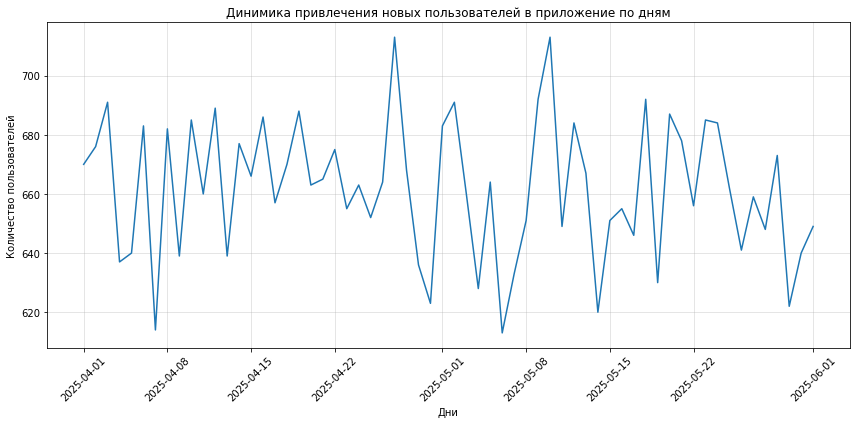

In [ ]:
# Сгруппируем пользователй по дням регистрации
users_per_days = sollmafin_hist_df.groupby('first_dt')['user_id'].nunique().reset_index(name='user_count')

# Строим график
plt.figure(figsize=(12,6))
plt.plot(users_per_days['first_dt'], users_per_days['user_count'])

# Оформляем график
plt.title('Динимика привлечения новых пользователей в приложение по дням')
plt.xlabel('Дни')
plt.ylabel('Количество пользователей')
plt.xticks(rotation=45)
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()


Динамика привлечения новых пользователей демонстрирует относительную стабильность на протяжении всего периода с апреля по июнь 2025 года. Количество новых пользователей колеблется в диапазоне от 615 до 710 человек в день.

**Промежуточный вывод** <br>
Приложение стабильно привлекает около 700 пользователей в день на протяжении всего рассматриваемого периода.

**Задача 2.2.** Анализ воронок событий.
- Построим классическую и пошаговую воронки;
- Охарактеризуем пользовательский путь в приложении и определим узкие места воронки.


Перед тем как построить конверсию, определим порядок пользовательского пути. Для этого посмотрим на события в приложении одного пользователя.

In [ ]:
# Выводим информацию о действиях одного пользователя
display(sollmafin_hist_df[sollmafin_hist_df['user_id'] == 'df7b9aae-7475-4878-a8c7-9bd3002fa226'])

,user_id,country_code,platform,first_ts,first_dt,event_ts,event_name,amount,asset,risk_level
13,df7b9aae-7475-4878-a8c7-9bd3002fa226,BR,mobile,2025-04-30 11:19:58,2025-04-30,2025-04-30 11:19:58,install / open_web,NaN,NaN,NaN
14,df7b9aae-7475-4878-a8c7-9bd3002fa226,BR,mobile,2025-04-30 11:19:58,2025-04-30,2025-04-30 11:20:06,introduction,NaN,NaN,NaN
15,df7b9aae-7475-4878-a8c7-9bd3002fa226,BR,mobile,2025-04-30 11:19:58,2025-04-30,2025-04-30 18:11:47,registration,NaN,NaN,NaN
16,df7b9aae-7475-4878-a8c7-9bd3002fa226,BR,mobile,2025-04-30 11:19:58,2025-04-30,2025-04-30 18:11:52,main_page,NaN,NaN,NaN
17,df7b9aae-7475-4878-a8c7-9bd3002fa226,BR,mobile,2025-04-30 11:19:58,2025-04-30,2025-04-30 18:13:54,onboarding_complete,NaN,NaN,NaN
18,df7b9aae-7475-4878-a8c7-9bd3002fa226,BR,mobile,2025-04-30 11:19:58,2025-04-30,2025-05-01 01:55:59,first_deposit,88.0,NaN,NaN
19,df7b9aae-7475-4878-a8c7-9bd3002fa226,BR,mobile,2025-04-30 11:19:58,2025-04-30,2025-05-01 12:32:40,asset_purchase,NaN,option,high


В качестве основы возьмем следующий путь пользователя:
- `install / open_web` — установка мобильного приложения / открытие веб-версии
- `introduction` — странита приветсвие
- `registration` — регистрация
- `main_page` — главная страница
- `onboarding_complete` — завершение онбординга
- `first_deposit` — первое пополнение счета (депозит)
- `asset_purchase` — приобретение актива
- `second_deposit` — второй депозит

Перейдем к расчёту и визуализации классической и step‑by‑step воронок.

In [ ]:
# Задаём порядок шагов воронки пользовательского пути
funnel_steps = ['install / open_web',
                'introduction',
                'registration',
                'main_page',
                'onboarding_complete',
                'first_deposit',
                'asset_purchase',
                'second_deposit']

# Считаем уникальных пользователей на каждом шаге и сортируем по порядку воронки
funnel_data = sollmafin_hist_df.groupby('event_name')['user_id'].nunique().reindex(funnel_steps).reset_index(name='users_n')

# Строим классическая воронка
funnel_data['conversion_%'] = ((funnel_data['users_n'] / funnel_data['users_n'].iloc[0]) * 100).round(1)

# Строим step‑by‑step воронку
funnel_data['conversion_from_previous_step_%'] = (funnel_data['users_n'] / funnel_data['users_n'].shift(1) * 100).round(1)

# Выводим таблицу
display(funnel_data)

,event_name,users_n,conversion_%,conversion_from_previous_step_%
0,install / open_web,41032,100.0,NaN
1,introduction,41032,100.0,100.0
2,registration,38133,92.9,92.9
3,main_page,35040,85.4,91.9
4,onboarding_complete,34337,83.7,98.0
5,first_deposit,27685,67.5,80.6
6,asset_purchase,15392,37.5,55.6
7,second_deposit,5408,13.2,35.1


Перейдем к визуализации воронок.

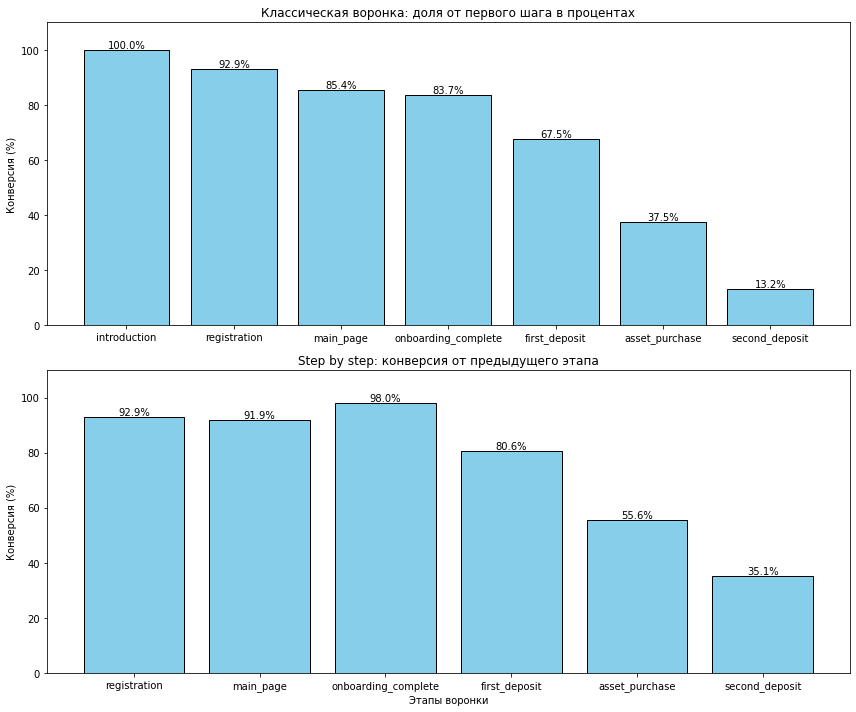

In [ ]:
# Строим две столбчатые диаграммы
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Классическая воронка, отфильтрованная с шага introduction
axes[0].bar(funnel_data['event_name'][1:], funnel_data['conversion_%'][1:], color='skyblue', edgecolor='black')
axes[0].set_title('Классическая воронка: доля от первого шага в процентах')
axes[0].set_ylabel('Конверсия (%)')
axes[0].set_ylim(0, 110)
# Добавляем подписи значений на столбцы
for x, y in zip(funnel_data['event_name'][1:], funnel_data['conversion_%'][1:]):
    if pd.notna(y):
        axes[0].text(x, y, f'{y:.1f}%', ha='center', va='bottom')

# Step by step воронка, отфильтрованная с шага registration
axes[1].bar(funnel_data['event_name'][2:], funnel_data['conversion_from_previous_step_%'][2:], color='skyblue', edgecolor='black')
axes[1].set_title('Step by step: конверсия от предыдущего этапа')
axes[1].set_ylabel('Конверсия (%)')
axes[1].set_xlabel('Этапы воронки')
axes[1].set_ylim(0, 110)
# Добавляем подписи значений
for x, y in zip(funnel_data['event_name'][2:], funnel_data['conversion_from_previous_step_%'][2:]):
    if pd.notna(y):
        axes[1].text(x, y, f'{y:.1f}%', ha='center', va='bottom')



plt.tight_layout()
plt.show()

*Классическая воронка* <br>
На втором этапе (`introduction`) мы видим 100% пользователей, что может указывать на то, эти этапы происходят в пользовательском пути одновременно. На третьем этапе - регистрация - остается 92.9% пользователей. 85.4% переходят на главную страницу (`main_page`), а завершают онбординг (`onboarding_complete`) 83.7%, то есть примерно каждый шестой не доходит до этой стадии. Первое пополнение счета (`first_deposit` - первый депозит) совершают только 67.5%, а приобретают актив (`asset_purchase`) только 37.5%. До второго депозита доходят только 13.2% пользователей. Самые большие потери происходят на этапах приобретения актива и второго депозита.

*Воронка step-by-step*<br>
На первых трех этапах после `introduction` - это `registration`, `main_page`, `onboarding_complete` - конверсия находится в пределах 91-98%. Существенная потеря обнаружена между шагами `onboarding_complete` и `first_deposit` — конверсия составила 80.6%, то есть теряется 19.4% пользователей на этапе первого пополнения счёта. Еще большие потери происходят на следующих двух этапах: после первого депозита только 55.6% пользователей приобретают актив, а из тех, кто купил актив, лишь 35.1% доходят до второго депозита.

**Промежуточный вывод** <br>
Анализ воронки событий выявил ключевые зоны потери пользователей. Начальные этапы (до завершения онбординга) демонстрируют достаточно высокую конверсию. Основные потери начинаются на этапе монетизации: первый депозит совершают только 67.5% пользователей, а приобретают актив лишь 37.5%. Наиболее критичное падение происходит между первым депозитом и покупкой актива — конверсия составляет всего 55.6% (теряется более 44% пользователей, дошедших до депозита). До второго депозита доходят лишь 13.2% от начального числа пользователей, что означает потерю более 80% пользователей от момента установки приложения / открытия веб-версии. Таким образом, узкими местами в воронке являются этапы конверсии из первого депозита в покупку актива и из покупки актива в повторный депозит.

**Задача 2.3.** Влияние уровня риска актива на открытие второго депозита.
- Изучим, как уровень риска первого актива влияет на конверсию во второй депозит.  

Посчитаем воронку во второй депозит в разрезе уровня риска первого актива.

In [ ]:
# Объединяем данные о покупке актива и втором депозите с учетом уровня риска
second_deposit_df = pd.merge(
    sollmafin_hist_df[sollmafin_hist_df['event_name'] == 'asset_purchase'][['user_id', 'risk_level']],
    sollmafin_hist_df[sollmafin_hist_df['event_name'] == 'second_deposit'][['user_id', 'event_name']],
    how='inner',
    on='user_id'
)

# Считаем количество уникальных пользователей, купивших актив, в разрезе уровней риска
funnel_to_asset_purchase = (sollmafin_hist_df[sollmafin_hist_df['event_name'] == 'asset_purchase'].
                            groupby('risk_level')['user_id'].
                            nunique().
                            reset_index(name='n_users_asset_purchase')
)

# Считаем количество уникальных пользователей, сделавших второй депозит, для каждого уровня риска первого актива
funnel_to_second_deposit = (second_deposit_df.
                            groupby('risk_level')['user_id'].
                            nunique().
                            reset_index(name='n_users_second_deposit')
)

# Формируем итоговую таблицу воронки и рассчитываем конверсию из покупки актива во второй депозит
funnel = pd.merge(funnel_to_asset_purchase, funnel_to_second_deposit, on='risk_level', how='left')
funnel['cr (%)'] = (funnel['n_users_second_deposit'] / funnel['n_users_asset_purchase'] * 100).round(2)

# Выводим результат c сотрировкой
display(funnel.sort_values(by='cr (%)'))



,risk_level,n_users_asset_purchase,n_users_second_deposit,cr (%)
0,high,7740,2040,26.36
2,medium,5325,2288,42.97
1,low,2327,1080,46.41


Конверсия в открытие второго депозита зависит от типа риска, приоретенного актива. Для активов с высоким риском (`high`), конверсия составила 26,36%, для среднего (`medium`) и низкого (`low`) уровня риска  -  42,97% и 46.41%, соответственно.

**Промежуточный вывод** <br>
Анализ показал: уровень риска приобиетаемого актива влияет на открытие второго депозита. Пользователи, которые выбрали высокорискованные активы, реже, чем остальные - кто приобрел активы со средним и низким риском - возвращаются и открывают второй депозит. Подтверждается утвреждение, что пользователи, которые купили высокорискованные активы и потеряли в итоге деньги, зачастую перестают инвестировать.

**Задача 2.4.** Анализ ключевой метрики на исторических данных.
- На исторических данных рассчитаем значение ключевой метрики — средней суммы всех депозитов на одного пользователя. Будем учитывать всех пользователей, которые взаимодействовали с сервисом. Это позволит зафиксировать базовый уровень монетизации.
- Визуализируем данные, где необходимо.

In [ ]:
# Посчитаем среднию сумму всех депозитов на одного пользователя
amount_sum = sollmafin_hist_df.groupby('user_id')['amount'].sum().reset_index()
mean_amount = amount_sum['amount'].mean().round(2)
std = amount_sum['amount'].std().round(2)

print(f'Среднее суммы всех депозитов на одного пользователя: {mean_amount:.2f}')
print(f'Стандартное отклонение величины: {std:.2f}')

Среднее суммы всех депозитов на одного пользователя: 91.56
Стандартное отклонение величины: 80.39


Рассмотрим распределение сумм депозитов на пользователя.

In [ ]:
# Изучаем статистические показатели сумм депозитов
print("Описание распределения:")
print(amount_sum['amount'].describe(percentiles=[0.05, 0.25, 0.30, 0.5, 0.75, 0.95, 0.99]).round(2))

Описание распределения:
count    41032.00
mean        91.56
std         80.39
min          0.00
5%           0.00
25%          0.00
30%          0.00
50%         96.00
75%        133.00
95%        241.45
99%        318.00
max        656.00
Name: amount, dtype: float64


Учитывая, что ключевая метрика расчитанна на всех пользователей (кто запускал приложение и открывад веб-версию), около 30% пользователей в выборке не совершали депозитов. Также есть небольшая часть пользователи, которые выбиваются из основного распределения - их депозит превышает 99-ый процентиль (99-й процентиль — 318.00). Только нужно принимать во внимание, что 99-ый процентиль "занижен" значениями пользователей, которые не совершали депозитов. Максимальная сумма депозита составила 656 у.е. при стандартном отклонении 80.39, что говорит о том, что в целом ключевая метрика варьируется не так сильно.

Далее построим гистограмму распределения сумм депозитов на пользователя.

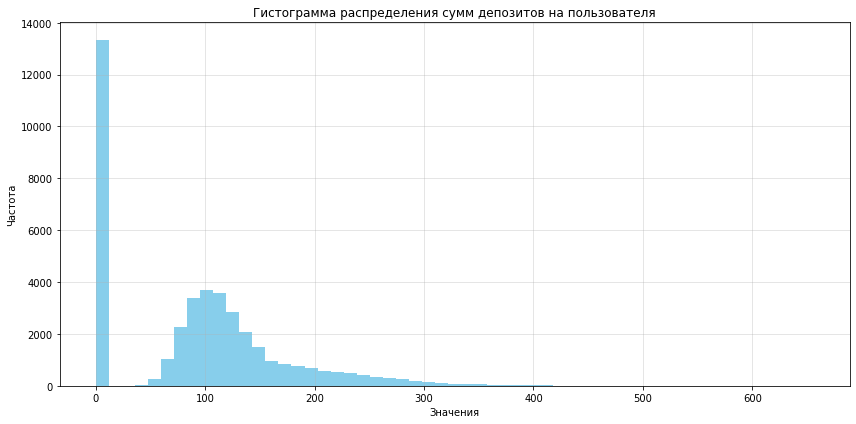

In [ ]:
# Строим график
plt.figure(figsize=(12,6))
plt.hist(amount_sum['amount'], bins=55, color='skyblue')

# Оформляем график
plt.title('Гистограмма распределения сумм депозитов на пользователя')
plt.xlabel('Значения')
plt.ylabel('Частота')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()




На гистограмме у распределения заметен длинный правый хвост, который говорит о наличии сегмента пользователей с относительно большими депозитами.

Теперь построим boxplot график, чтобы детальнее посмотреть на значения с большими суммами депозита.

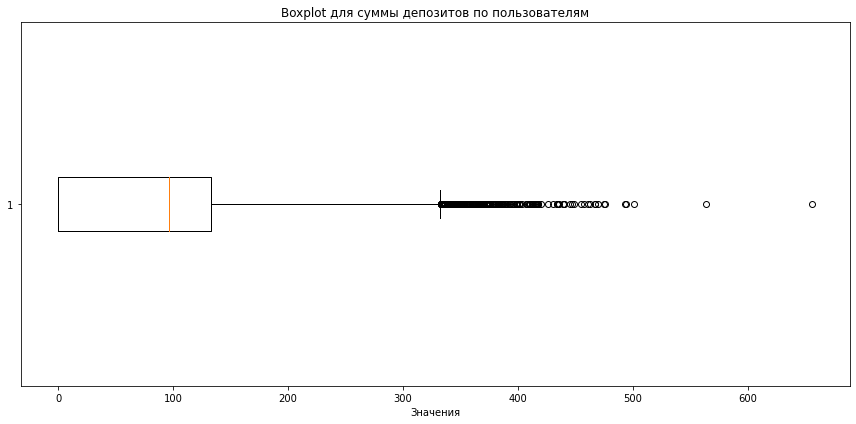

In [ ]:
# Строим график
plt.figure(figsize=(12, 6))
plt.boxplot(amount_sum['amount'], vert=False)

# Оформляем график
plt.xlabel('Значения')
plt.title('Boxplot для суммы депозитов по пользователям')
plt.tight_layout()
plt.show()

График boxplot показывает, что есть буквально несколько высоких значений по сумме депозита (больше 500), которые визуально отделены от основного распеределения. Это в целом говорит о том, что в распеределении нет крайне высоких значений метрики.

**Промежуточный вывод** <br>
На основе проведенного статистического анализа можно сделать следующие выводы:<br>
Базовый уровень монетизации: Средняя сумма всех депозитов на одного пользователя составляет 91.56 у.е. Однако это значение сильно подвержено влиянию неплатящей аудитории.<br>
Активность аудитории: Анализ перцентилей показал, что минимум 25% пользователей из всей выборки не совершили ни одного депозита.<br>
Вариативность данных: Стандартное отклонение (80.39) сопоставимо со средним значением.
Структура распределения: Распределение имеет правостороннюю асимметрию. График Boxplot подтверждает наличие единичных выбросов (свыше 500 у.е.), которые визуально отделены от основной массы данных. Тем не менее, максимальное значение (656 у.е.) не является экстремальным, что свидетельствует об отсутствии "китов", которые могли бы исказить общую статистику.



---

## Часть 2

### 3. Исследование результатов А/В эксперимента
В этой части проекта загрузим данные с результатами эксперимента (датасет `/datasets/pa_sollmafin_abt.csv `). Проверим корректность данных и проведём предобработку. Зафиксируем основную информацию о данных и предобработке в кратком промежуточном выводе.
Затем проведём анализ результатов А/В-эксперимента.


In [ ]:
# Выгружаем данные в датафрейм и приведем к типу datetime64 столцы с датой и временем
sollmafin_abt_df = pd.read_csv('https://code.s3.yandex.net/datasets/pa_sollmafin_abt.csv', parse_dates=['first_ts', 'first_dt', 'event_ts'])

In [ ]:
# Выведем первые 5 строк и информации о датасете
display(sollmafin_abt_df.head(5))
display(sollmafin_abt_df.info())

,user_id,country_code,platform,first_ts,first_dt,event_ts,event_name,ab_test,group,amount,asset,risk_level
0,c430acb5-c6bf-43cf-8e2d-7ab9ce0d2c8a,BR,mobile,2025-06-07 19:55:51,2025-06-07,2025-06-07 19:55:51,install / open_web,onboarding_test,test,NaN,NaN,NaN
1,c430acb5-c6bf-43cf-8e2d-7ab9ce0d2c8a,BR,mobile,2025-06-07 19:55:51,2025-06-07,2025-06-07 19:55:54,introduction,onboarding_test,test,NaN,NaN,NaN
2,c430acb5-c6bf-43cf-8e2d-7ab9ce0d2c8a,BR,mobile,2025-06-07 19:55:51,2025-06-07,2025-06-08 06:18:09,registration,onboarding_test,test,NaN,NaN,NaN
3,c430acb5-c6bf-43cf-8e2d-7ab9ce0d2c8a,BR,mobile,2025-06-07 19:55:51,2025-06-07,2025-06-08 06:18:13,main_page,onboarding_test,test,NaN,NaN,NaN
4,c430acb5-c6bf-43cf-8e2d-7ab9ce0d2c8a,BR,mobile,2025-06-07 19:55:51,2025-06-07,2025-06-08 06:33:40,onboarding_complete,onboarding_test,test,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54805 entries, 0 to 54804
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   user_id       54805 non-null  object        
 1   country_code  54805 non-null  object        
 2   platform      54805 non-null  object        
 3   first_ts      54805 non-null  datetime64[ns]
 4   first_dt      54805 non-null  datetime64[ns]
 5   event_ts      54805 non-null  datetime64[ns]
 6   event_name    54805 non-null  object        
 7   ab_test       54805 non-null  object        
 8   group         54805 non-null  object        
 9   amount        7843 non-null   float64       
 10  asset         3750 non-null   object        
 11  risk_level    3750 non-null   object        
dtypes: datetime64[ns](3), float64(1), object(8)
memory usage: 5.0+ MB


None

In [ ]:
# Отобразим количество уникальных значений в столбцах датафрейма
print('Количество уникальных значений в столбцах датафрейма\n'
      f'Размер датафрейма: {sollmafin_abt_df.shape[0]}\n')

for column in ['user_id', 'first_ts', 'first_dt', 'event_ts', 'amount']:
    count = sollmafin_abt_df[column].nunique()
    print(f'Количество уникальных значений в {column}: {count}\n')

Количество уникальных значений в столбцах датафрейма
Размер датафрейма: 54805

Количество уникальных значений в user_id: 9415

Количество уникальных значений в first_ts: 9371

Количество уникальных значений в first_dt: 14

Количество уникальных значений в event_ts: 53563

Количество уникальных значений в amount: 420



In [ ]:
# Познакомимся с уникальными значениями в столбцах (ограничим число отображения до 15)
for column in ['country_code', 'platform', 'event_name', 'asset', 'risk_level', 'ab_test', 'group']:
    unique_vals = sollmafin_abt_df[column].unique()
    total_count = len(unique_vals)
        # Если уникальных значений больше 15, показываем сокращенный вывод
    if total_count > 20:
        print(f'{column}: {unique_vals[:15]}\n')
    else:
        print(f'{column}: {unique_vals}\n')

country_code: ['BR' 'MX' 'CO' 'AR']

platform: ['mobile' 'web']

event_name: ['install / open_web' 'introduction' 'registration' 'main_page'
 'onboarding_complete' 'first_deposit' 'asset_purchase' 'second_deposit']

asset: [nan 'crypto' 'stock' 'option']

risk_level: [nan 'high' 'low' 'medium']

ab_test: ['onboarding_test']

group: ['test' 'control']



In [ ]:
# Опеределим временные диапазон столбца с временем событий

time_min, time_man = sollmafin_abt_df['event_ts'].min(), sollmafin_abt_df['event_ts'].max()
print(f'Временной диапозон событий: {time_min} - {time_man}')



Временной диапозон событий: 2025-06-02 00:27:50 - 2025-06-22 13:37:05


Описание данных после предварительного знакомства с датасетом `pa_sollmafin_abt.csv`<br>
Датасет состоит из 11 полей и 54805 содержит действия новых пользователей во время А/В-эксперимента.

*Пользовательская база* <br>
- 9415 уникальных пользователя

*География и устройства*<br>
- Пользователи распределены по 4 странам: `BR` — Бразилия, `MX` — Мексика, `AR` — Аргентина, `CO` — Колумбия
-  2 типа устройств:mobile и web.

*Событийная часть*<br>
- 53563 пользовательских событий
- 7843 покупок актива
- данные охватывают события от установки/открытия сайта до второго депозита (`event_name`): `install / open_web`, `introduction`, `registration`, `main_page`, `onboarding_complete`, `first_deposit`, `asset_purchase`, `second_deposit`.

*Тип данных*<br>
- типы данных соответствуют значениям столбцов
- для поля amount понизим разрядность

*Временной диапозон*<br>
- в датасет вошли события с 1 по 22 июня, хотя эксперимент проводился на протяжении двух недель - со 2 по 15 июня

В дальнейшем анализе будем фильтровать данные по указанным двум неделям эксперимента.

In [ ]:
# Понизим разрядность amount с типом данных float64
sollmafin_abt_df['amount'] = pd.to_numeric(sollmafin_abt_df['amount'], downcast='float')

In [ ]:
# Отфильтруем данные по датам проведения эксперимента
start = pd.Timestamp('2025-06-02 00:00:00')
end = pd.Timestamp('2025-06-15 23:59:59')
sollmafin_сorr_df = sollmafin_abt_df[(sollmafin_abt_df['event_ts'] >= start) & (sollmafin_abt_df['event_ts'] <= end)]


Еще раз посмотрим на данные после фильтрации датасета.

In [ ]:
print(f'{sollmafin_сorr_df.info()}\n')

print(f'Количество уникальных пользователей: {sollmafin_сorr_df["user_id"].nunique()}')
print(f'Количество уникальных дней: {sollmafin_сorr_df["event_ts"].dt.date.nunique()}')


<class 'pandas.core.frame.DataFrame'>
Int64Index: 52393 entries, 0 to 54804
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   user_id       52393 non-null  object        
 1   country_code  52393 non-null  object        
 2   platform      52393 non-null  object        
 3   first_ts      52393 non-null  datetime64[ns]
 4   first_dt      52393 non-null  datetime64[ns]
 5   event_ts      52393 non-null  datetime64[ns]
 6   event_name    52393 non-null  object        
 7   ab_test       52393 non-null  object        
 8   group         52393 non-null  object        
 9   amount        6665 non-null   float32       
 10  asset         3114 non-null   object        
 11  risk_level    3114 non-null   object        
dtypes: datetime64[ns](3), float32(1), object(8)
memory usage: 5.0+ MB
None

Количество уникальных пользователей: 9415
Количество уникальных дней: 14


После фильтрации датасета по датам мы получили: 11 полей и 52393 действий новых пользователей во время А/В-эксперимента в период со 2 по 15 июня 2025 года включительно.

*Пользовательская база* не изменилась и составила 9415 пользователей.<br>
*Пользовательские события* включили 52393 действий пользователей, 6665 покупок активов. <br>
*Временной диапозон*: со 2 по 15 июня 2025 года (2 недели)


**Промежуточный вывод** <br>
В ходе первичного анализа датасета `pa_sollmafin_abt.csv`, содержащего 52393 записей о действиях новых пользователей в рамках А/В-эксперимента (период со 2 по 15 июня 2025 года), установлено, что пользовательская база насчитывает 9415 уникальных пользователей из четырех стран (Бразилия, Мексика, Аргентина, Колумбия), использующих два типа устройств (`mobile` и `web`). Событийная часть включает 52393 действия, охватывающих воронку от установки/открытия сайта до второго депозита, и содержит 6665 записей о пополнении актива. Качество данных оценивается как высокое: типы данных приведены в соответствие содержанию столбцов (включая оптимизацию разрядности для поля `amount`), структура событий позволяет детально проследить путь пользователя в сервисе, а пользователи разделены на две группы (`test`, `control`) в рамках одного эксперимента (`onboarding_test`).
Данные были офильтрованы по датам эксперимента.

**Задача 3.1.** Анализ аудитории эксперимента.
- Проверим корректность распределения новых пользователей по группам А/В-эксперимента.
- Построим график и сформулируем промежуточный вывод.

In [ ]:
# Сгруппируем пользователей по группам и проверим количество групп для каждого пользователя
split_check = sollmafin_сorr_df.groupby('user_id')['group'].nunique().reset_index(name='group_count')

# Вывежем количество пользователей, которые попали в несколько групп, если таковые имеются
print(f'Количество пользователей, которые попали в две группы: {(split_check["group_count"] > 1).sum()}')


Количество пользователей, которые попали в две группы: 0


Далее посмотрим на распределение пользователей по группам А/В-эксперимента.

In [ ]:
# Считаем количество уникальных пользователей в каждой группе
a = sollmafin_сorr_df[sollmafin_сorr_df['group'] == 'control']['user_id'].nunique()
b = sollmafin_сorr_df[sollmafin_сorr_df['group'] == 'test']['user_id'].nunique()


print(f'Количество пользователей в контрольной группе: {a}')
print(f'Количество пользователей в тестовой группе: {b}')

P = 100 * (a-b)/a
print(f"Процентная разница между группами: {P:.2f}%")

Количество пользователей в контрольной группе: 4847
Количество пользователей в тестовой группе: 4568
Процентная разница между группами: 5.76%


Визуализируем распределение пользователей по группам.

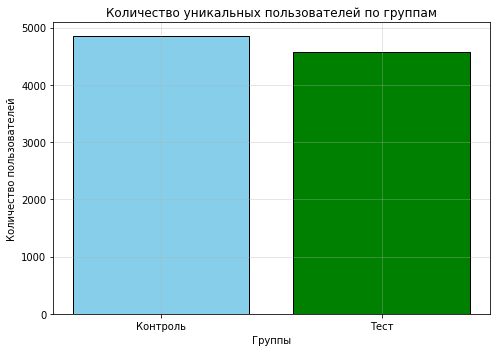

In [ ]:
# Визуализируем различия в количестве уникальных пользователей по группам
# Создаем контейнер графика и задаём размер
plt.figure(figsize=(7, 5))

# Строим столбчатую диаграмму
plt.bar(['Контроль', 'Тест'], [a, b], color=['skyblue', 'green'], edgecolor='black')

# Оформляем график
plt.title('Количество уникальных пользователей по группам')
plt.xlabel('Группы')
plt.ylabel('Количество пользователей')
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

**Промежуточный вывод** <br>
В результате проверки выяснилось, что в данных нет пользователей, которые попали сразу в две группы. Распределение по группам составило: 4847 пользователей в контрольной и 4568 - в тестовой. Относительная разница между гуппами - 5.76%, что не является критическим для последующего анализа.

**Задача 3.2.** Сравнение воронок событий.
- Сравним пользовательский путь новых пользователей в тестовой и контрольной группах.
- Построим классическую и последовательную воронки, выполним визуализацию.

In [ ]:
# Задаём порядок шагов воронки пользовательского пути
funnel_steps = ['install / open_web',
                'introduction',
                'registration',
                'main_page',
                'onboarding_complete',
                'first_deposit',
                'asset_purchase',
                'second_deposit']

# Считаем уникальных пользователей сразу для всех групп и событий
funnel_data = (
    sollmafin_сorr_df[sollmafin_сorr_df['event_name'].isin(funnel_steps)]
    .groupby(['event_name', 'group'])['user_id']
    .nunique()
    .unstack()
    .reindex(funnel_steps)
    .rename_axis(None, axis=1)
)

# Считаем классическую воронку
funnel_classic = (funnel_data / funnel_data.iloc[0] * 100).round(2)

# Считаем step-by-step воронку
funnel_step_by_step = (funnel_data / funnel_data.shift(1) * 100).round(2)

# Формируем финальные таблицы
funnel_classic_compare = funnel_classic.iloc[1:].reset_index().rename(columns={'event_name': 'steps'})
funnel_step_by_step_compare = funnel_step_by_step.iloc[1:].reset_index().rename(columns={'event_name': 'steps'})

# Объединяем результаты в одну таблицу по колонке 'steps'
final_funnel_compare = funnel_classic_compare.merge(
    funnel_step_by_step_compare,
    on='steps',
    suffixes=('_classic', '_s_by_s')
)
# Выводим итоговую таблицу
display(final_funnel_compare)



,steps,control_classic,test_classic,control_s_by_s,test_s_by_s
0,introduction,100.00,100.00,100.00,100.00
1,registration,90.88,91.02,90.88,91.02
2,main_page,83.93,83.67,92.35,91.92
3,onboarding_complete,81.89,73.60,97.57,87.96
4,first_deposit,58.90,58.12,71.93,78.97
5,asset_purchase,29.50,36.87,50.09,63.43
6,second_deposit,8.81,15.94,29.86,43.23


Перейдем к визуализации: построим столбчатые диаграммы для классической и последовательной воронок.

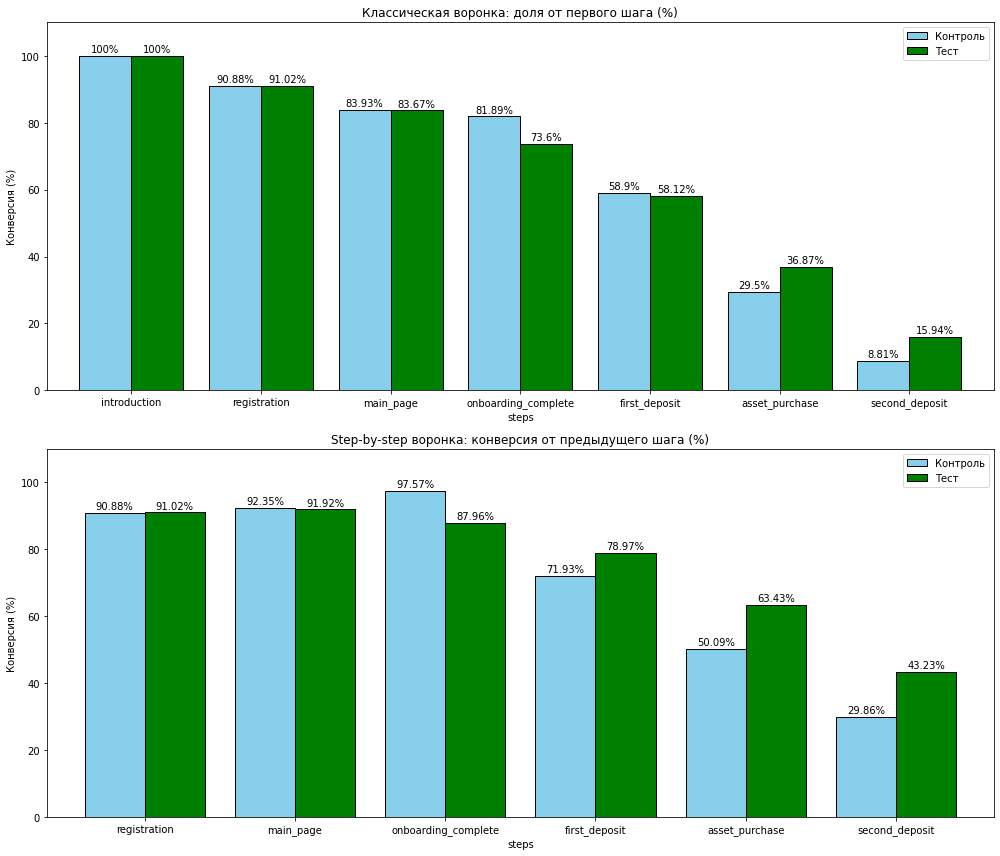

In [ ]:
# Ставим шаги в индекс для подписей по оси X
funnel_plot = final_funnel_compare.set_index('steps')

# Создаем общее полотно
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Собираем и оформляем график с классической воронкой
ax1 = funnel_plot[['control_classic', 'test_classic']].plot(
    kind='bar', ax=axes[0], color=['skyblue', 'green'], edgecolor='black', width=0.8
)
ax1.set_title('Классическая воронка: доля от первого шага (%)')
ax1.set_ylabel('Конверсия (%)')
ax1.set_ylim(0, 110)
ax1.legend(['Контроль', 'Тест'])

# Собираем и оформляем график с step-by-Step воронка
ax2 = funnel_plot[['control_s_by_s', 'test_s_by_s']].iloc[1:].plot(
    kind='bar', ax=axes[1], color=['skyblue', 'green'], edgecolor='black', width=0.8
)
ax2.set_title('Step-by-step воронка: конверсия от предыдущего шага (%)')
ax2.set_ylabel('Конверсия (%)')
ax2.set_ylim(0, 110)
ax2.legend(['Контроль', 'Тест'])

# Общий цикл для добавления подписей на оба графика
for ax in [ax1, ax2]:
    for p in ax.patches:
        height = p.get_height()
        ax.text(
            p.get_x() + p.get_width() / 2.,
            height + 0.5,
            f'{height:g}%',
            ha="center",
            va="bottom"
        )
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

**Классическая воронка** <br>
На этапе регистрации (`registration`) показатели почти идентичны: 90.9% в контроле и 91% в тесте. Переход на главную страницу (`main_page`) также на практически одном уровне - около 83%. Однако на стадии завершения онбординга (`onboarding_complete`) в тестовой группе есть заметная просадка - до 73.6%, в то время как в контроле 81.9%. Несмотря на это, конверсия в первый пополнение счета (`first_deposit`) в обеих группах выравнивается и составляет около 58%. Основные различия проявляются на финальных этапах: в тестовой группе активы приобретают (`asset_purchase`) 36.9% пользователей, а в контроле 29.5%. До второго депозита (`second_deposit`) в тесте доходят 15.9%, что значительно выше результата контрольной группы в 8.8%. Самые большие потери в обеих воронках по-прежнему приходятся на приобретение актива и второй депозит, но тестовая группа показывает гораздо лучшую удерживаемость на этих стадиях.

**Step-by-step воронка** <br>
На первых этапах конверсия из регистрации в переход на главную страницу (`main_page`) в обеих группах достаточно близки - 92.3% в контроле и 91.9% в тесте. Однако на этапе `onboarding_complete` в тестовой группе наблюдается падение до 88%, тогда как в контроле этот показатель составляет 97.6%. Однако, те пользователи тестовой группы, которые завершили онбординг, совершают первый депозит (`first_deposit`) чаще - 79%, в то время как в контроле  72% . На этапе приобретения актива (`asset_purchase`) конверсия в тестовой группе выше, чем в контрольной: 63.4% и 50.1%, соответственно. Самая значительная разница между группами видна на втором депозите (`second_deposit`) - в тестовой группе почти каждый второй (43.2%) повторно пополняет счёт, в то время как в контроле это делает примерно каждый третий (29.9%). Таким образом, несмотря на потери на этапе онбординга, тестовый вариант значительно лучше ведёт пользователей к последующему инвестиционному действию.

**Промежуточный вывод** <br>
На начальных этапах регистрации и перехода на главную страницу показатели в обеих группах практически идентичны. Различия фиксируется на этапе завершения онбординга, где конверсия из установки приложения/открытии веб-страницы в тестовой группе проседает до 73.6% (в контрольной - 81.9%). Это указывает на то, что информация о возможных потерях и высоких рисках в обновленной версии онбординга всё же отпугивает часть новых пользователей и они не проходят онбординг до конца. Несмотря на эти потери, пользователи тестовой группы, прошедшие обучение, гораздо активнее совершают целевые действия: конверсия в первый депозит у них выше на 7 процентных пунктов. В финале воронки преимущество теста становится еще более очевидным, так как приобретение актива и второй депозит совершаются значительно чаще. В итоге обновленный онбординг с углубленной информацией, с одной стороны, отсеивает часть аудитории, но, с другой стороны, приводит к более высокой доли пользователей, которые совершают целевые действия в продукте.


**Задача 3.3.** Влияние новой фичи на конверсию во второй депозит с учётом уровня риска купленного актива.
- Проанализируем, как категория риска купленного актива влияет на вероятность открытия второго депозита в тестовой и контрольной группах.
- Сравним результаты и оценим, есть ли статистически значимая разница между группами.

In [ ]:
# Объединяем данные о покупке актива и втором депозите с учетом уровня риска
second_deposit_abt_df = pd.merge(
    sollmafin_сorr_df[sollmafin_сorr_df['event_name'] == 'asset_purchase'][['user_id', 'group', 'risk_level']],
    sollmafin_сorr_df[sollmafin_сorr_df['event_name'] == 'second_deposit'][['user_id']],
    how='inner',
    on='user_id'
)

# Считаем по контрольной и тестовой группам количество уникальных пользователей,
# купивших актив, с учетом уровня риска
funnel_abt_to_asset_purchase = (sollmafin_сorr_df[sollmafin_сorr_df['event_name'] == 'asset_purchase'].
                            groupby(['risk_level', 'group'])['user_id'].
                            nunique().
                            reset_index(name='n_users_asset_purchase')
)

# Считаем по контрольной и тестовой группам количество уникальных пользователей,
# сделавших второй депозит, с учетом уровня риска
funnel_abt_to_second_deposit = (second_deposit_abt_df.
                            groupby(['risk_level', 'group'])['user_id'].
                            nunique().
                            reset_index(name='n_users_second_deposit')
)

# Формируем итоговую таблицу воронки и рассчитываем конверсию из покупки актива во второй депозит по групам
funnel_abt = pd.merge(funnel_abt_to_asset_purchase, funnel_abt_to_second_deposit, on = ['risk_level', 'group'], how='left')
funnel_abt['cr (%)'] = (funnel_abt['n_users_second_deposit'] / funnel_abt['n_users_asset_purchase'] * 100).round(2)

# Выводим результат c сотрировкой
display(funnel_abt.sort_values(by=['group', 'cr (%)']))



,risk_level,group,n_users_asset_purchase,n_users_second_deposit,cr (%)
0,high,control,728,168,23.08
4,medium,control,470,164,34.89
2,low,control,232,95,40.95
1,high,test,627,256,40.83
5,medium,test,640,266,41.56
3,low,test,417,206,49.40


В итоговой таблице представлены значения конверсии во второй депозит в разрезе уровней риска приобретенных активов. Наиболее заметный прирост зафиксирован в категории высокорисковых активов: в контрольной группе конверсия составила 23.1%, тогда как в тестовой - 40.8%, что дает разницу более чем в 17 процентных пунктов. Для низкорисковых и среднерисковых активов также наблюдается положительная динамика: 40.9% в контроле и 49.4% в тесте для активов с низким риском; 34.9% в контрольной и 41.6% в тестовой группе для активов со средним риском.
Таким образом, фича оказывает положительное влияние на конверсию во второй депозит для купленных активов всех уровней риска, но в большей степери для высокоросковых активов.<br>



Оценим, являются ли полученные различия статистически значимыми.<br>

**Нулевую гипотезу** оперделим следующим образом: конверсия во второй депозит в контрольной и тестовой группе не различаются.

**Альтернативная гипотеза**: конверсия во второй депозит в тестовой группе выше, чем в контрольной.

Статистический тест: z-тест пропорций (поскольку мы сравниваем пропорции в двух выборках и это величина, которая считается на пользователя). Ниже проверяем условия применимости z-теста пропорции.

Поскольку у нас три уровня риска, проводим три теста. Будем применять поправку Бонферрони для множественной проверки гипотез.







In [ ]:
# Проведем статистический тест
# Задаим уровень значимости (альфа) с поправкой Бонферрони
alpha = 0.05 / 3

# Проверяем условия применимости z-теста пропорции

for risk in funnel_abt['risk_level'].unique():

    # Собираем данные для контрольной группы
    n_a = funnel_abt[(funnel_abt['risk_level'] == risk) & (funnel_abt['group'] == 'control')]['n_users_second_deposit'].iloc[0]
    m_a = funnel_abt[(funnel_abt['risk_level'] == risk) & (funnel_abt['group'] == 'control')]['n_users_asset_purchase'].iloc[0]

    # Собираем данные для тестовой группы
    n_b = funnel_abt[(funnel_abt['risk_level'] == risk) & (funnel_abt['group'] == 'test')]['n_users_second_deposit'].iloc[0]
    m_b = funnel_abt[(funnel_abt['risk_level'] == risk) & (funnel_abt['group'] == 'test')]['n_users_asset_purchase'].iloc[0]

    # Расчитываем конверсии
    p_a = n_a / m_a
    p_b =  n_b / m_b

    # Проверяем условия применимости z-теста пропорции
    print(f'Уровень риска актива: {risk}\n\nПроверяем условия применимости z-теста пропорции:')
    if (p_a*n_a > 10)and((1-p_a)*n_a > 10)and(p_b*n_b > 10)and((1-p_b)*n_b > 10):
        print('предпосылка о достаточном количестве данных выполняется\n')
    else:
        print('предпосылка о достаточном количестве данных НЕ выполняется\n')

    print(f'Конверсия в контрольной группе: {p_a:.3f}')
    print(f'Конверсия в тестовой группе: {p_b:.3f}')
    print(f'Absolute Lift: {(p_b - p_a):.3f}')
    print(f'Relative Lift: {(p_b / p_a - 1):.1%}\n')

    # Определяем уровень значимости
    __, p_value = proportions_ztest([n_b, n_a], [m_b, m_a], alternative='larger')

    print(f'p-value = {p_value:.4f}\n')
    if p_value > alpha:
        print('Нулевая гипотеза не отвергается: конверсия в тестовой группе не выше, чем в контрольной группе\n')

    else:
        print('Нулевая гипотеза отвергается: конверсия в тестовой группе выше, чем в контрольной группе\n')

    print("-" * 90)


Уровень риска актива: high

Проверяем условия применимости z-теста пропорции:
предпосылка о достаточном количестве данных выполняется

Конверсия в контрольной группе: 0.231
Конверсия в тестовой группе: 0.408
Absolute Lift: 0.178
Relative Lift: 76.9%

p-value = 0.0000

Нулевая гипотеза отвергается: конверсия в тестовой группе выше, чем в контрольной группе

------------------------------------------------------------------------------------------
Уровень риска актива: low

Проверяем условия применимости z-теста пропорции:
предпосылка о достаточном количестве данных выполняется

Конверсия в контрольной группе: 0.409
Конверсия в тестовой группе: 0.494
Absolute Lift: 0.085
Relative Lift: 20.6%

p-value = 0.0193

Нулевая гипотеза не отвергается: конверсия в тестовой группе не выше, чем в контрольной группе

------------------------------------------------------------------------------------------
Уровень риска актива: medium

Проверяем условия применимости z-теста пропорции:
предпосылка о д

Статистический тест показал, что в случае высокорисковых и низкорисковых активов мы можем отклонить нулевую гипотезу и утверждать, что конверсия во второй депозит в тестовой группе статистически значимо выше, чем в контрольной.  Конверсия для высокорисковых активов в тестовой группе выросла на 17 п.п. или на 76.9% по сравнению с контрольной. Для низкорисковых активов конверсия в тестовой группе выросла на 6 п.п. или на 19.1% по сравнению с контролем. Для среднерисковых активов статистически значимых различий не обнаружено.

**Промежуточный вывод** <br>
Новый онбординг статистически значимо увеличивает конверсию во второй депозит для купленных активов низкого и высокого риска: иначе говоря, для этих типов активов пользователи в тестовой группе чаще, чем в контрольной открывают второй депозит. Для среднерисковых активов статистически значимых различий обнаружено не было.

**Задача 3.4.** Анализ метрик А/В-эксперимента. Проанализируем следующие метрики:
- Ключевая метрика — средняя сумма всех депозитов на одного пользователя (включая тех, кто установил приложение или открыл веб-версию).
- Барьерная метрика — конверсия из регистрации в первый депозит.
- Вспомогательная метрика 1 — конверсия из первого депозита во второй.
- Вспомогательная метрика 2 — средняя сумма всех депозитов на пользователя, который открыл хотя бы один депозит.

Для каждой метрики выведим:
- значения в контрольной и тестовой группах,
- абсолютные и относительные изменения значений в тестовой группе по сравнению с контрольной.

После этого проверим статистическую значимость различий метрик между группами эксперимента.

Для ключевой метрики также изучите:
- накопленную динамику изменения по дням эксперимента для каждой группы,
- стабильность p-value во время эксперимента.



Рассчитаем ключевую, барьерную и вспомогательные метрики.

In [ ]:
# Создаем датафреймы для каждой группы
control_abt = sollmafin_сorr_df[sollmafin_сorr_df['group'] == 'control']
test_abt = sollmafin_сorr_df[sollmafin_сorr_df['group'] == 'test']

# Рассчитываем метрики
# Ключевая метрика - средняя сумма всех депозитов на одного пользователя
control_amount_sum = control_abt.groupby('user_id')['amount'].sum()
test_amount_sum = test_abt.groupby('user_id')['amount'].sum()
control_mean_per_user = control_amount_sum.mean()
test_mean_per_user = test_amount_sum.mean()

# Барьерная метрика - конверсия из регистрации в первый депозит
# Создадим пивот-таблицу для расчета конверсий
funnel_counts = sollmafin_сorr_df.pivot_table(
        index='event_name',
        columns='group',
        values='user_id',
        aggfunc='nunique'
)
# Считаем конверсии
control_reg_to_dep = (funnel_counts.loc['first_deposit', 'control'] / funnel_counts.loc['registration', 'control'])

test_reg_to_dep = (funnel_counts.loc['first_deposit', 'test'] / funnel_counts.loc['registration', 'test'])

# Вспомогательная метрика 1 — конверсия из первого депозита во второй
control_dep_to_dep = (funnel_counts.loc['second_deposit', 'control'] / funnel_counts.loc['first_deposit', 'control'])
test_dep_to_dep = (funnel_counts.loc['second_deposit', 'test'] / funnel_counts.loc['first_deposit', 'test'])

# Вспомогательная метрика 2 — средняя сумма всех депозитов на пользователя, который открыл хотя бы один депозит
funnel_target = ['first_deposit', 'second_deposit']
control_sum_per_payer = control_abt[control_abt['event_name'].isin(funnel_target)].groupby('user_id')['amount'].sum()
test_sum_per_payer = test_abt[test_abt['event_name'].isin(funnel_target)].groupby('user_id')['amount'].sum()
control_mean_per_payer = control_sum_per_payer.mean()
test_mean_per_payer = test_sum_per_payer.mean()

# Собираем данные в одну таблицу
result_df = pd.DataFrame({
    'Метрика': [
        'Ключевая метрика',
        'Барьерная метрика',
        'Вспомогательная метрика 1',
        'Вспомогательная метрика 2'
    ],
    'Control': [
        control_mean_per_user,
        control_reg_to_dep,
        control_dep_to_dep,
        control_mean_per_payer
    ],
    'Test': [
        test_mean_per_user,
        test_reg_to_dep,
        test_dep_to_dep,
        test_mean_per_payer
    ]
})

# Добавим колонки с абсолютными и относительными изменениями
result_df['Absolute Lift'] = result_df['Test'] - result_df['Control']
result_df['Relative Lift (%)'] = ((result_df['Test'] / result_df['Control'] - 1) * 100).round(2)


# Выводим таблицу
result_df


,Метрика,Control,Test,Absolute Lift,Relative Lift (%)
0,Ключевая метрика,75.938522,76.976357,1.037834,1.37
1,Барьерная метрика,0.648127,0.638528,-0.009599,-1.48
2,Вспомогательная метрика 1,0.149562,0.274200,0.124637,83.33
3,Вспомогательная метрика 2,128.922592,132.439926,3.517334,2.73


Результаты показывают положительную динамику в тестовой группе. <br>
**Ключевая метрика** (средняя сумма депозитов на пользователя) выросла на 1.04, что соответствует относительному приросту в 1.37%. <br>  При этом **барьерная метрика** (конверсия из регистрации в первый депозит) немного просела - с 0.65 до 0.64, что дает снижение на 1.5%. <br>  **Вспомогательная метрика 1** (конверсия из первого во второй депозит) продемонстрировала значительный рост: показатель увеличился с 0.15 до 0.27, что составляет 83.3% прироста относительно контрольной группы. <br>  Также выросла и **вспомогательная метрика 2** (средняя сумма депозитов на платящего пользователя) с 128.9 до 132.4. Таким образом, несмотря на небольшие потери в конверсии на этапе завершения онбординга, фича лучше стимулирует повторные платежи и увеличивает средную сумму депозитов активной аудитории.

Теперь проверим статистическую значимость различий метрик между группами эксперимента. Поскольку мы проводим несколько тестов (4 теста) на одних данных, будем принять поправку Бонферрони.

In [ ]:
# Создадим функцию для выведения результата сравнения p-value с порогом alpha
def check_hypothesis(p_value, alpha):
    """
    Функция проверяет статистическую значимость, сравнивая p-value с порогом alpha.
    """
    print('Результат статистического теста для сравнения групп:')
    print(f'p-value = {p_value:.4f}')
    if p_value > alpha:
        print('Нулевая гипотеза не отвергается: значимых различий между группами не обнаружено.\n')
    else:
        print('Нулевая гипотеза отвергается: между группами обнаружены статистически значимые различия.\n')

Формулируем гипотезы по ключевой метрике.<br>
**Нулевая гипотеза**: средняя сумма всех депозитов на одного пользователя (включая тех, кто установил приложение или открыл веб-версию) в контрольной и тестовой группе не различаются.<br>
**Альтернативная гипотеза**: средняя сумма всех депозитов на одного пользователя (включая тех, кто установил приложение или открыл веб-версию) в тестовой  группе выше, чем в контрольной группе.


In [ ]:
# Статистический тест Стьюдента для ключевой метрики - средняя сумма всех депозитов на одного пользователя
# Определяем порог значимости
alpha = 0.05 / 4

# Проводим тест
_, p_value_km = ttest_ind(control_amount_sum, test_amount_sum)

# Выводим результат теста
check_hypothesis(p_value_km, alpha)




Результат статистического теста для сравнения групп:
p-value = 0.6213
Нулевая гипотеза не отвергается: значимых различий между группами не обнаружено.



Формулируем гипотезы по барьерной метрике.<br>
**Нулевая гипотеза**: конверсия из регистрации в первый депозит в контрольной и тестовой группе не различаются.<br>
**Альтернативная гипотеза**: конверсия из регистрации в первый депозит в тестовой группе ниже, чем в контрольной группе.

In [ ]:
# Статистический тест z-теста пропорции для барьерной метрики (конверсия из регистрации в первый депозит) вместе с
# предварительной проверкой условия для его применимости
# Собираем данные для контрольной группы
n_a_bm = funnel_counts.loc['first_deposit', 'control']
m_a_bm = funnel_counts.loc['registration', 'control']

# Собираем данные для тестовой группы
n_b_bm = funnel_counts.loc['first_deposit', 'test']
m_b_bm = funnel_counts.loc['registration', 'test']


# Расчитываем конверсии
p_a = n_a_bm / m_a_bm
p_b =  n_b_bm / m_b_bm

# Проверяем условия применимости z-теста пропорции
print('Проверяем условия применимости z-теста пропорции:')
if (p_a*n_a_bm > 10)and((1-p_a)*n_a_bm > 10)and(p_b*n_b_bm > 10)and((1-p_b)*n_b_bm > 10):
    print('предпосылка о достаточном количестве данных выполняется\n')
else:
    print('предпосылка о достаточном количестве данных НЕ выполняется\n')

# Определяем уровень значимости (для параметра alternative выбиарем значение  smaller,
# потому что метрика в экспериментальной группе ниже, чем в котрольной)
__, p_value_bm = proportions_ztest([n_b_bm, n_a_bm], [m_b_bm, m_a_bm], alternative='smaller')

# Выводим результат теста
check_hypothesis(p_value_bm, alpha)

Проверяем условия применимости z-теста пропорции:
предпосылка о достаточном количестве данных выполняется

Результат статистического теста для сравнения групп:
p-value = 0.1770
Нулевая гипотеза не отвергается: значимых различий между группами не обнаружено.



Формулируем гипотезы по вспомогательной метрике 1.<br>
**Нулевая гипотеза**: конверсия из первого депозита во второй в контрольной и тестовой группе не различаются.<br>
**Альтернативная гипотеза**: конверсия из первого депозита во второй в тестовой группе выше, чем в контрольной группе.

In [ ]:
# Статистический тест z-теста пропорции для первой вспомогательной метрики (конверсия из первого депозита во второй) вместе с
# предварительной проверкой условия для его применимости
# Собираем данные для контрольной группы
n_a_am = funnel_counts.loc['second_deposit', 'control']
m_a_am = funnel_counts.loc['first_deposit', 'control']

# Собираем данные для тестовой группы
n_b_am = funnel_counts.loc['second_deposit', 'test']
m_b_am = funnel_counts.loc['first_deposit', 'test']


# Расчитываем конверсии
p_a = n_a_am / m_a_am
p_b =  n_b_am / m_b_am

# Проверяем условия применимости z-теста пропорции
print('Проверяем условия применимости z-теста пропорции:')
if (p_a*n_a_am > 10)and((1-p_a)*n_a_am > 10)and(p_b*n_b_am > 10)and((1-p_b)*n_b_am > 10):
    print('предпосылка о достаточном количестве данных выполняется\n')
else:
    print('предпосылка о достаточном количестве данных НЕ выполняется\n')

# Определяем уровень значимости (для параметра alternative выбиарем значение larger,
# потому что метрика в экспериментальной группе выше, чем в котрольной)
__, p_value_am1 = proportions_ztest([n_b_am, n_a_am], [m_b_am, m_a_am], alternative='larger')

# Выводим результат теста
check_hypothesis(p_value_am1, alpha)

Проверяем условия применимости z-теста пропорции:
предпосылка о достаточном количестве данных выполняется

Результат статистического теста для сравнения групп:
p-value = 0.0000
Нулевая гипотеза отвергается: между группами обнаружены статистически значимые различия.



Формулируем гипотезы по вспомогательной метрике 2.<br>
**Нулевая гипотеза**: средняя сумма всех депозитов на одного пользователя (включая тех, кто установил приложение или открыл веб-версию) в контрольной и тестовой группе не различаются.<br>
**Альтернативная гипотеза**: средняя сумма всех депозитов на одного пользователя (включая тех, кто установил приложение или открыл веб-версию) в тестовой группе выше, чем в контрольной группе.

In [ ]:
# Статистический тест Стьюдента для второй вспомогательной метрики - средняя сумма всех депозитов на пользователя,
# который открыл хотя бы один депозит
_, p_value_am2 = ttest_ind(control_sum_per_payer, test_sum_per_payer)

# Выводим результат теста
check_hypothesis(p_value_am2, alpha)


Результат статистического теста для сравнения групп:
p-value = 0.2064
Нулевая гипотеза не отвергается: значимых различий между группами не обнаружено.



Добавим результаты тестов (p-value) в таблицу с метриками.

In [ ]:
# Создаем список с рассчитанными p-value
p_values = [p_value_km, p_value_bm,   p_value_am1,  p_value_am2 ]

# Добавляем колонку в существующий датафрейм
result_df['p-value'] = p_values

# Добавляем колонку с информацией о том, статистически значимые различия между группами или нет
result_df['Статвывод'] = result_df['p-value'].apply(lambda x: 'статистически значимо' if x < alpha else 'не значимо')

# Округляем значения
result_df['p-value'] = result_df['p-value'].round(4)

# Выводим итоговую таблицу
result_df

,Метрика,Control,Test,Absolute Lift,Relative Lift (%),p-value,Статвывод
0,Ключевая метрика,75.938522,76.976357,1.037834,1.37,0.6213,не значимо
1,Барьерная метрика,0.648127,0.638528,-0.009599,-1.48,0.1770,не значимо
2,Вспомогательная метрика 1,0.149562,0.274200,0.124637,83.33,0.0000,статистически значимо
3,Вспомогательная метрика 2,128.922592,132.439926,3.517334,2.73,0.2064,не значимо


Мы проверили статистические различия между группами для следующих метрик:<br>
- Ключевая метрика — средняя сумма всех депозитов на одного пользователя (включая тех, кто установил приложение или открыл веб-версию).
- Барьерная метрика — конверсия из регистрации в первый депозит.
- Вспомогательная метрика 1 — конверсия из первого депозита во второй.
- Вспомогательная метрика 2 — средняя сумма всех депозитов на пользователя, который открыл хотя бы один депозит.

Результаты статистического теста показывают, что изменения в ключевой метрике (средняя сумма депозитов на пользователя) не являются значимыми (p-value 0.6213). Уменьшение барьерной метрики в тестовой группе не является стастистически значимым  различием (p-value 0.1770), что позволяет утверждать, что негативного влияния фичи на конверсию из регистрации в первый депозит не выявлено. Среди дополнительных показателей статистически значимым является рост только по вспомогательной метрике 1 (конверсия из первого во второй депозит), где зафиксирован значительный прирост в 83% (p-value < 0.0001). При этом изменения во вспомогательной метрике 2 (средняя сумма депозитов на пользователя, у которого был открыт хотя бы один депозит) оказались стататистически незначимым (p-value 0.2064), несмотря на небольшой положительный лифт в 2.7%.

**Промежуточный вывод** <br>
После проведения статистических тестов можно заключить, что мы не нашли подтверждения тому, что фича оказала значимое положительное влияние на ключевую метрику - среднюю сумму всех депозитов на одного пользователя, который использовал приложение. При этом барьерная метрика не показала статистически значимых негативных изменений, что снимает опасения по поводу оттока осторожных новичков из-за информации о рисках. Основные изменения зафиксированы в поведении платящей аудитории. Одна из вспомогательных метрик - конверсия из первого депозита во второй - показала статистически значимый рост на 83%. Вторая вспомогательная метрика - средняя сумма депозитов на платящего пользователя - продемонстрировала положительную динамику (лифт 2.7%), но этот результат не является статистически значимым.

Таким образом, фича успешно сработала на дополнительную гипотезу (удержание и повторные пополнения): пользователи после нового онбординга чаще возвращаются в приложение и совершают второй депозит. В рамках эксперимента не удалось найти подтверждения для гипотезы роста (ключевая метрика). Зато положительный момент в том, что не удалось подтвердить гипотезу риска (снижение первичной конверсии из-за информирования о возможных потерях).

Далее рассчитаем и визуализирум для ключевой метрики накопленную динамику изменения по дням эксперимента для каждой группы.

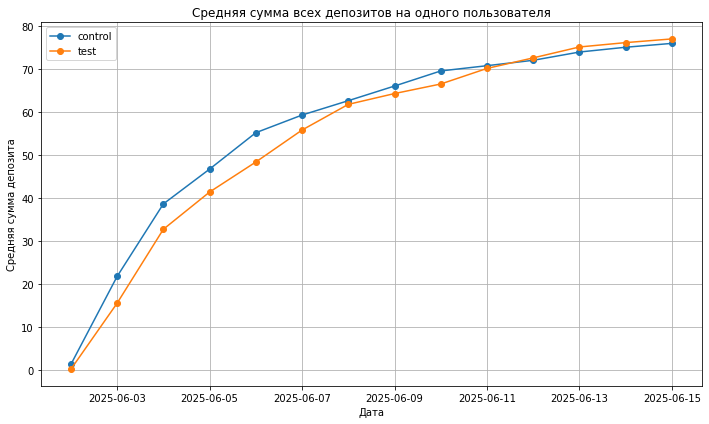

In [ ]:
# Создадим столбец с датой события
sollmafin_сorr_df['event_day'] = sollmafin_сorr_df['event_ts'].dt.date

# Сохраним отсотрированные по возрастанию даты
dates = sorted(sollmafin_сorr_df['event_day'].unique())

# Пустой список для результатов
records = []

# Создаем цикл для рассчета комулятивной ключевой метрики по дням
for current_date in dates:
    # Оставляем данные до текущей даты включительно
    data_to_date = sollmafin_сorr_df[sollmafin_сorr_df['event_day'] <= current_date]
    # Считаем сумму депозитов до текущей даты по группам
    amounts_sum = data_to_date.groupby('group')['amount'].sum().reset_index(name='amount_sum')
    # Считаем количество пользователей до текущей даты по группам
    users_by_group = data_to_date.groupby('group')['user_id'].nunique().reset_index(name='user_count')
    # Объединяем результаты в таблицу
    df_merged = pd.merge(amounts_sum, users_by_group, on = 'group', how = 'inner')
    # Считаем среднюю сумму депозита на пользователя
    df_merged['amount_per_user'] = df_merged['amount_sum'] / df_merged['user_count']
    # Добавляем в таблицу дату
    df_merged['date'] = current_date
    records.append(df_merged)

# Собираем результат в итоговый датафрейм
amount_df = pd.concat(records)

# Строим график
plt.figure(figsize=(10, 6))
for group in amount_df['group'].unique():
   group_data = amount_df[amount_df['group'] == group]
   plt.plot(group_data['date'], group_data['amount_per_user'], marker = 'o', label=group)
plt.title('Средняя сумма всех депозитов на одного пользователя')
plt.xlabel('Дата')
plt.ylabel('Средняя сумма депозита')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Кумулятивный график показывает, что значения ключевой метрики в тестовой и контрольной группах остаются близкими на протяжении всей дистанции теста. При этом заметно, что средняя сумма депозитов в тестовой группе постепенно растет относительно контроля и к 10-му дню эксперимента начинает его превосходить. Такая динамика может указывать на наличие слабовыраженного положительного эффекта от фичи, для подтверждения которого текущему тесту не хватило статистической мощности (требуется выборка большего размера или более длительный период наблюдения).

Далее исследуем стабильность p-value во время эксперимента.

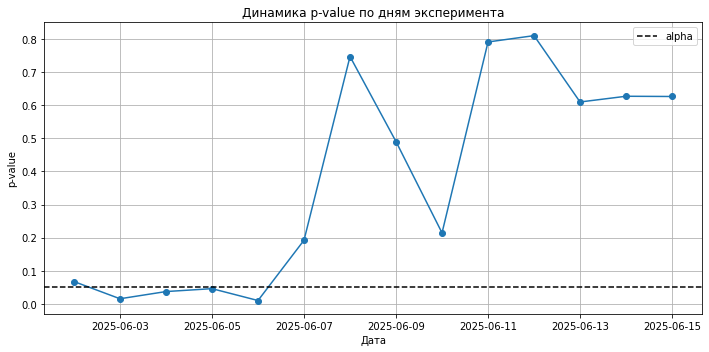

In [ ]:
# Пустой список для результатов
pval_records = []

# Расчёт p-value по дням
for current_date in dates:
    # Оставляем данные до текущей даты включительно
    active_to_date = sollmafin_сorr_df[sollmafin_сorr_df['event_day'] <= current_date]

    # Отдельно собираем данные по группам
    control_abt = active_to_date[active_to_date['group'] == 'control']
    test_abt = active_to_date[active_to_date['group'] == 'test']

    # Считаем сумму депозита на одного пользователя
    control = control_abt.groupby('user_id')['amount'].sum()
    test = test_abt.groupby('user_id')['amount'].sum()

    #расчет p-value
    p_val_ab = ttest_ind(control, test, equal_var=False).pvalue

    pval_records.append({
        'date': current_date,
        'p_value': p_val_ab
    })


# Собираем в DataFrame
pvalue_df = pd.DataFrame(pval_records)

# График
plt.figure(figsize=(10, 5))

# Построение линий графика
plt.plot(pvalue_df['date'], pvalue_df['p_value'], marker = 'o')


plt.axhline(y=0.05, linestyle='--', color='black', label='alpha')
plt.title('Динамика p-value по дням эксперимента')
plt.xlabel('Дата')
plt.ylabel('p-value')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

На графике видно, что со второго по пятый день эксперимента p-value был ниже порога значимости (альфа = 0.05), но после привысил его и больше не опускался ниже. При этом с 5 по 10 день эксперимента значение p-value сильно колеблется, но после стабилизируется.

**Промежуточный вывод** <br>
Кумулятивный график показал что значения ключевой метрики в обоих группах достаточно близки на протяжении всего теста. Однако при этом динамика метрики в тестовой группе показывает рост относительно контроля к концу второй недели. На основе этого наблюдения можно допустить, что существует слабый положительный эффекта от фичи, но для подтверждения которого текущему тесту не хватило статистической мощности или времени наблюдения. Стоит отметить, что это допущение достаточно сильное, если учесть график динамики p_value по дням: с 5 дня и до завершения эксперимента p_value был постоянно выше порога значимости (с 10 дня видны признаки того, что показатель стабилизируется).

---

### 4. Анализ изменений суммы депозитов на платящего пользователя

Новая фича могла повлиять на поведение пользователей.
- Пользователи, которые раньше вносили небольшие суммы, могли стать более осторожными, сократить свои вложения или совсем перестать платить. Это отразится в снижении 25-го перцентиля суммы депозитов в тестовой группе.
- Пользователи, которые склонны к более крупным инвестициям, могли сильнее вовлечься в продукт и начать вносить больше средств. Это отразится в росте 75-го перцентиля.

Используя бутстрап, сравним разницы перцентилей (25, 50, 75) суммы всех депозитов на платящего пользователя в контрольной и тестовой группах:
- Построим доверительные интервалы для разницы между группами для каждого перцентиля.
- Интерпретируем изменения в контексте сформулированной выше гипотезы.
- Визуализируем результат бутстрап-теста.

Сначала построим доверительные интервалы для разницы между группами для 25, 50, 75 перцентилей.

In [ ]:
# Фиксируем сид для воспроизводимости
np.random.seed(341)

# Подготавливаем данные (суммы только по платящим пользователям)
steps = ['first_deposit', 'second_deposit']
control_payers = sollmafin_сorr_df[(sollmafin_сorr_df['group'] == 'control') & (sollmafin_сorr_df['event_name'].isin(steps))]
test_payers = sollmafin_сorr_df[(sollmafin_сorr_df['group'] == 'test') & (sollmafin_сorr_df['event_name'].isin(steps))]
control_payers_sum = control_payers.groupby('user_id')['amount'].sum()
test_payers_sum = test_payers.groupby('user_id')['amount'].sum()

n_iterations = 1000
percentiles = [25, 50, 75]

# Создаем словарь для хранения результатов по каждому перцентилю
boot_results = {}
for p in percentiles:
    boot_results[p] = []

# Основной цикл бутстрапа
for i in range(n_iterations):
    # Генерируем подвыборки с возвращением для обоих групп
    boot_control = np.random.choice(control_payers_sum, size=len(control_payers_sum), replace=True)
    boot_test = np.random.choice(test_payers_sum, size=len(test_payers_sum), replace=True)
    # Вложенный цикл для списка прецентилей
    for p in percentiles:
        # Рассчитываем p-й перцентиль для обеих групп
        control_p = np.percentile(boot_control, p)
        test_p = np.percentile(boot_test, p)
        # Сохраняем разницу между значениями тестовой и контрольной групп
        boot_results[p].append(test_p - control_p)

# Вывод результатов (после завершения всех итераций)
print("Результаты бутстрап-анализа разности перцентилей:\n")

for p in percentiles:
    # Создаём массив из накопленных разниц для конкретного перцентиля
    boot_diffs_p = np.array(boot_results[p])

    # Доверительный интервал разницы (перцентильный метод)
    diff_ci = np.percentile(boot_diffs_p, [2.5, 97.5])

    # Вывод результатов по твоему шаблону
    print(f"{p}-й перцентиль контрольной группы: {np.percentile(control_payers_sum, p):.2f}")
    print(f"{p}-й перцентиль тестовой группы: {np.percentile(test_payers_sum, p):.2f}")
    print(f"95% доверительный интервал разности {p}-х перцентилей: [{diff_ci[0]:.2f}, {diff_ci[1]:.2f}]")
    print('-' * 70)


Результаты бутстрап-анализа разности перцентилей:

25-й перцентиль контрольной группы: 94.00
25-й перцентиль тестовой группы: 44.00
95% доверительный интервал разности 25-х перцентилей: [-52.00, -46.00]
----------------------------------------------------------------------
50-й перцентиль контрольной группы: 115.00
50-й перцентиль тестовой группы: 88.00
95% доверительный интервал разности 50-х перцентилей: [-31.00, -22.00]
----------------------------------------------------------------------
75-й перцентиль контрольной группы: 147.00
75-й перцентиль тестовой группы: 165.50
95% доверительный интервал разности 75-х перцентилей: [10.99, 27.00]
----------------------------------------------------------------------


Мы провели бутстрап-анализ для сравним разницы перцентилей (25, 50, 75) суммы всех депозитов на платящего пользователя в контрольной и тестовой группах. В результате мы получили распределения разницы перцентилей и доверительный интервал для них. Если доверительный интервал не пересекает ноль, то можно сделать вывод о статистической значимости разницы между группами. Если же интервал включает ноль, то статистически значимой разницы нет.

**25-й и 50-й перцентили суммы депозитов** - падение <br>
Доверительные интервалы не содержат ноль и находятся полностью в отрицательной зоне [-52, -46] и [-31, -22]. Различия статистически значимы: пользователи, которые раньше вносили небольшие и средние суммы (контрольная группа), в тестовой группе стали платить меньше.

**75-й перцентиль суммы депозитов** - рост <br>
Доверительный интервал не содержит ноль, находится в положительной зоне [10.99, 27.00]. Различия также статистически значимы. Группа пользователей, которые склонны к более крупным инвестициям, в тестовой группе стала платить больше, чем в контрольной.


Теперь визуализируем результат бутстрап-теста.

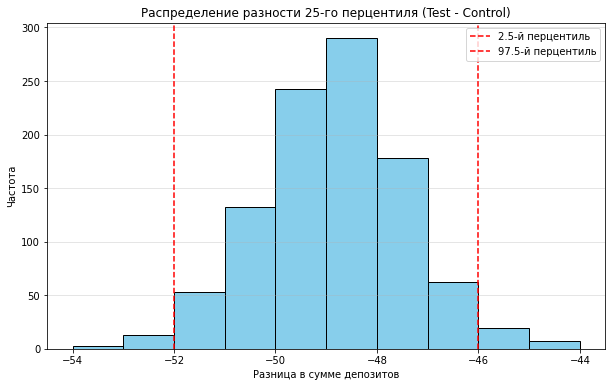

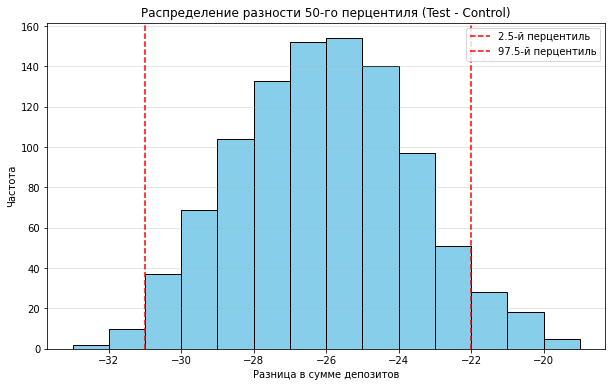

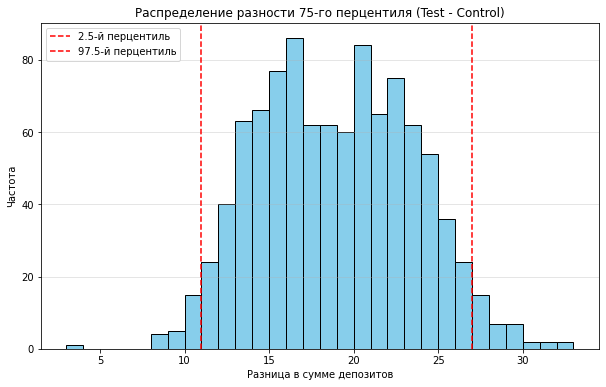

In [ ]:
# Создаем цикл для построения гистограмм
for p in percentiles:
    # Создаём массив из накопленных разниц для конкретного перцентиля
    boot_diffs_p = np.array(boot_results[p])

    # Доверительный интервал разницы (перцентильный метод)
    diff_ci = np.percentile(boot_diffs_p, [2.5, 97.5])

    # Формируем для каждой гистограммы сетку корзин (bins) с шагом 1 для устранения разрывов на графике
    bins_range = np.arange(boot_diffs_p.min(), boot_diffs_p.max() + 1, 1)

    # Визуализация
    plt.figure(figsize=(10, 6))
    plt.hist(boot_diffs_p, bins=bins_range, color='skyblue', edgecolor='black')

    # Добавляем линии доверительного интервала
    plt.axvline(diff_ci[0],  color='red', linestyle='--', label='2.5-й перцентиль')
    plt.axvline(diff_ci[1], color='red', linestyle='--', label='97.5-й перцентиль')

    # Оформляем график
    plt.title(f"Распределение разности {p}-го перцентиля (Test - Control)")
    plt.xlabel("Разница в сумме депозитов")
    plt.ylabel("Частота")
    plt.legend()
    plt.grid(axis='y', alpha=0.4)
    plt.show()



**Промежуточный вывод** <br>
На этом этапе анализа мы изучали то, как фича (новый онбординг) влияет на поведение платящих пользователей. Мы обнаружили статистически значимые различия между группами.

Во-первых, пользователи, которые раньше вносили небольшие и средние суммы (25-й и 50-й перцентили), в тестовой группе стали платить меньше. Возможно, информация о рисках в новом онбординге сделала осторожных пользователей еще более осторожными, и они стали вносить депозиты гораздо меньшего размера.

Во-вторых, группа пользователей, которые склонны к более крупным инвестициям (50-й перцентиль), в тестовой группе стала платить больше, чем в контрольной. По всей видимости, новый контент повысил вовлеченность этой части аудитории, стимулируя их вносить более крупные суммы. Иными словами, вовлеченные пользователи стали глубже разбираются в инвестировании и увеличивают сумму вложений.

---

### 5. Выводы



В этом проекте мы исследовали влияние нового отнбординга (фичи) на инвестиционное поведение пользователей международного мобильного приложения для онлайн-торговли финансовыми активами SollmaFin.  Предполагалось, что обновленный обучающий онбординг  повысит финансовую грамотность пользователей и они чаще будут покупать активы и открывать повторные депозиты.

Обновленный онбординг показал значительный рост удержания пользователей и повторного пополнения депозита: конверсия из первого депозита во второй показала статистически значимый увеличение на 83%. При этом барьерная метрика - конверсия из регистрации в первый депозит - не упала, а ключевая метрика - средняя сумма всех депозитов на одного пользователя - показала небольшой, но статистически незначимый lift в 1.37%. Еще одна вспомогательная метрика - средняя сумма депозита для платящего пользователя -  показала рост в 2.73%, но он тоже не был статистически значимым. В целом критерий успеха эксперимента можно считать достигнутым: ключевая и барьерная метрики не упали, а одна из вспомогательных показала значительный рост.

Исследование воронок также показало, что хотя обновленный онбординг отсеивает часть аудитории, он приводит к более высокой доли пользователей, которые совершают целевые действия в продукте - приобретают активы и открывают второй депозит. Бутстрап-анализ подсветил еще один важный эффект фичи: "осторожные" пользователи снизили суммы депозитов, в то время как "вовлеченные" инвесторы стали вносить заметно больше средств. Поэтому ключевая метрика для тестовой группы не показала значительного роста: "осторожные" пользователи своим поведением сбалансировали "вовлеченных".

*Рекомендации*: <br>
Учитывая полярное поведение групп, целесообразно рассмотреть внедрение гибкой системы онбординга. Предоставление пользователю выбора между "быстрым стартом" и "глубоким погружением" может сохранить лояльность осторожных пользователей и при этом стимулировать вовлеченных инвесторов.

Необходимо детально изучить этап завершения онбординга, так как это единственный шаг, где конверсия в тесте ниже контроля

Стоит рассмотреть влияние фичи на дополнительных срезах, например, по географии (странам).







